In [1]:
from classy import Class
print("CLASS imported successfully")

[
    name
    for name in dir(Class)
    if "transfer" in name.lower()
    or "source" in name.lower()
]

import inspect

print("get_sources:")
print(inspect.getdoc(Class.get_sources))

print("\nget_transfer:")
print(inspect.getdoc(Class.get_transfer))

print("\nget_transfer_and_k_and_z:")
print(inspect.getdoc(Class.get_transfer_and_k_and_z))

CLASS imported successfully
get_sources:
Return the source functions stored in the perturbation module at all sampled (k, tau)

After integrating all perturbations (more precisely, all
transfer functions) over time, the CLASS perturbation module
stores a list of the most important combinations of them on a
grid of (k,tau) values. This includes the combinations used
later to compute the CMB and LSS observables. This function
retrieves these source functions directly from the CLASS
structure 'perturbations', and returns them together with the
values of k and tau at which they are sampled.

The output is a dictionary whose keys belong to the list:
-'p' for the CMB polarization source
-'phi' for the metric fluctuation phi of the Newtonian gauge
-'phi_plus_psi' for the metric fluctuation phi+psi of the Newtonian gauge
-'phi_prime' for the metric fluctuation phi' of the Newtonian gauge
-'psi' for the metric fluctuation psi of the Newtonian gauge
-'H_T_Nb_prime' for the metric fluctuation H_T

In [8]:
from classy import Class
import numpy as np


# ==================================================
# CLASS run retaining perturbation sources
# ==================================================
source_params = {
    "output": "tCl",
    "lensing": "no",
    "l_max_scalars": 300,

    "h": 0.6736,
    "omega_b": 0.02237,
    "omega_cdm": 0.1200,
    "A_s": 2.100e-9,
    "n_s": 0.9649,
    "tau_reio": 0.0544,
}

cosmo_sources = Class()
cosmo_sources.set(source_params)
cosmo_sources.compute()

sources, k_class, tau_class = cosmo_sources.get_sources()

print("Source keys:")
print(list(sources.keys()))

print("\nk range [1/Mpc]:")
print(k_class.min(), k_class.max(), len(k_class))

print("\ntau range [Mpc]:")
print(tau_class.min(), tau_class.max(), len(tau_class))

print("\nSource-array shapes:")
for key, value in sources.items():
    print(f"{key:20s} {np.asarray(value).shape}")

Source keys:
['t0', 't1', 't2']

k range [1/Mpc]:
7.054894542137852e-06 0.03840564977028892 376

tau range [Mpc]:
226.91080368070544 14174.556317279394 605

Source-array shapes:
t0                   (376, 605)
t1                   (376, 605)
t2                   (376, 605)


In [9]:
# ==================================================
# Inspect source channels for each contribution
# ==================================================
def get_component_sources(component):

    cosmo = Class()
    cosmo.set({
        **source_params,
        "temperature_contributions": component,
    })
    cosmo.compute()

    sources, k, tau = cosmo.get_sources()

    result = {
        key: np.asarray(value).copy()
        for key, value in sources.items()
    }

    cosmo.struct_cleanup()
    cosmo.empty()

    return result, k.copy(), tau.copy()


component_sources = {}

for label, component in {
    "SW": "tsw",
    "Doppler": "dop",
    "early_ISW": "eisw",
    "late_ISW": "lisw",
}.items():

    src, k, tau = get_component_sources(component)
    component_sources[label] = src

    print(f"\n{label}")
    for key, value in src.items():
        print(
            f"{key}: shape={value.shape}, "
            f"max_abs={np.max(np.abs(value)):.6e}"
        )


SW
t0: shape=(376, 605), max_abs=1.271558e-02
t1: shape=(376, 605), max_abs=0.000000e+00
t2: shape=(376, 605), max_abs=0.000000e+00

Doppler
t0: shape=(376, 605), max_abs=7.719352e-02
t1: shape=(376, 605), max_abs=0.000000e+00
t2: shape=(376, 605), max_abs=0.000000e+00

early_ISW
t0: shape=(376, 605), max_abs=1.109468e-03
t1: shape=(376, 605), max_abs=1.822085e-04
t2: shape=(376, 605), max_abs=0.000000e+00

late_ISW
t0: shape=(376, 605), max_abs=1.006587e-04
t1: shape=(376, 605), max_abs=2.068210e-05
t2: shape=(376, 605), max_abs=0.000000e+00


In [10]:
[
    name
    for name in dir(Class)
    if any(
        word in name.lower()
        for word in [
            "cl",
            "temperature",
            "harmonic",
            "perturb",
        ]
    )
]

['__class__',
 '__init_subclass__',
 '__subclasshook__',
 'baryon_temperature',
 'density_cl',
 'get_perturbations',
 'lensed_cl',
 'raw_cl',
 'struct_cleanup']

In [11]:
from scipy.integrate import trapezoid
from scipy.special import spherical_jn
import numpy as np

ell_test = 20

sw_t0 = component_sources["SW"]["t0"]
tau0 = tau[-1]

Delta_SW_l20 = np.empty_like(k)

for ik, kval in enumerate(k):
    x = kval * (tau0 - tau)

    Delta_SW_l20[ik] = trapezoid(
        sw_t0[ik] * spherical_jn(ell_test, x),
        tau,
    )

print("shape:", Delta_SW_l20.shape)
print("min/max:", Delta_SW_l20.min(), Delta_SW_l20.max())
print("finite:", np.all(np.isfinite(Delta_SW_l20)))

shape: (376,)
min/max: -0.008165308789826608 0.013349899790667396
finite: True


## Total TT spectrum from CLASS

This plot shows the standard flat-$\Lambda$CDM temperature power spectrum

$$
D_\ell^{TT} = \frac{\ell(\ell+1)}{2\pi} C_\ell^{TT}.
$$

It is the **total** CMB temperature power, including SW, Doppler and ISW contributions together.

- Low $\ell$: large angular scales.
- Peak near $\ell \simeq 220$: first acoustic peak.
- This is not yet E1-specific; it only confirms that CLASS is working correctly.

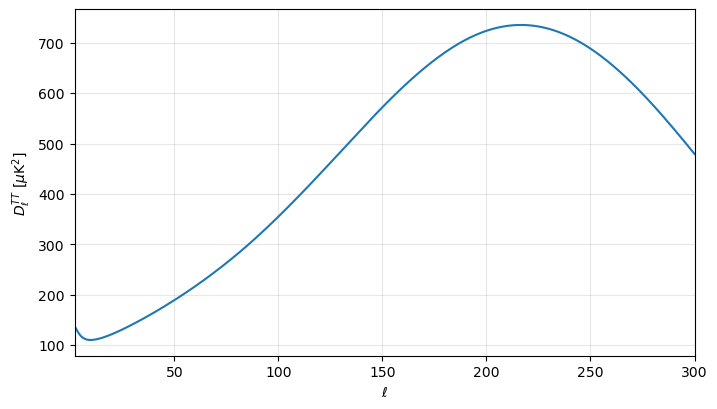

In [2]:
from classy import Class
import numpy as np
import matplotlib.pyplot as plt


# ==================================================
# First CLASS test: total unlensed TT spectrum
# ==================================================
params = {
    "output": "tCl",
    "lensing": "no",
    "l_max_scalars": 300,

    # Planck-like baseline cosmology
    "h": 0.6736,
    "omega_b": 0.02237,
    "omega_cdm": 0.1200,
    "A_s": 2.100e-9,
    "n_s": 0.9649,
    "tau_reio": 0.0544,
}

cosmo = Class()
cosmo.set(params)
cosmo.compute()

cl = cosmo.raw_cl(300)

ell = cl["ell"]
Dl_TT = ell * (ell + 1) * cl["tt"] / (2.0 * np.pi)

plt.figure(figsize=(8, 4.5))
plt.plot(ell[2:], Dl_TT[2:] * 1e12)
plt.xlim(2, 300)
plt.xlabel(r"$\ell$")
plt.ylabel(r"$D_\ell^{TT}\ [\mu{\rm K}^2]$")
plt.grid(alpha=0.3)
plt.show()

cosmo.struct_cleanup()
cosmo.empty()

## Separate CMB temperature contributions

CLASS is used to calculate the temperature power from:

$$
T_{\rm SW},\qquad
T_{\rm Doppler},\qquad
T_{\rm early\,ISW},\qquad
T_{\rm late\,ISW}.
$$

Each curve shows

$$
D_\ell^{X} = \frac{\ell(\ell+1)}{2\pi} C_\ell^{X},
$$

for one contribution $X$.

This lets us identify the multipoles where the ordinary SW contribution is strongest relative to Doppler and ISW. These spectra are not yet E1-specific; the E1 discrete mode spectrum will be added later.

### Flat ΛCDM cosmology

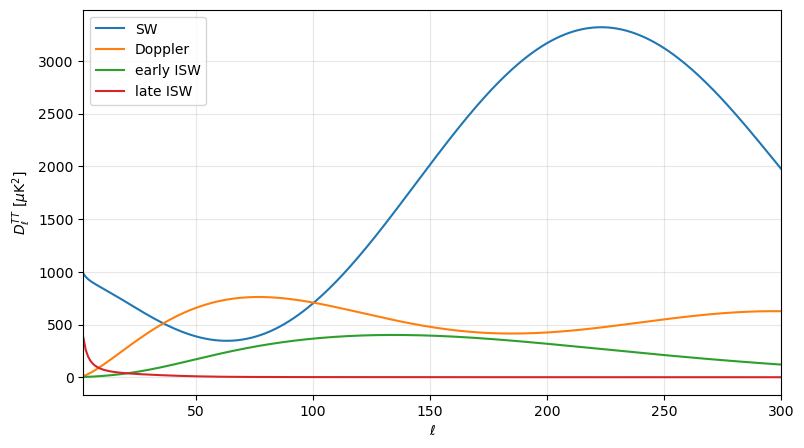

In [3]:
from classy import Class
import numpy as np
import matplotlib.pyplot as plt


# ==================================================
# Common cosmological settings
# ==================================================
base_params = {
    "output": "tCl",
    "lensing": "no",
    "l_max_scalars": 300,
    "h": 0.6736,
    "omega_b": 0.02237,
    "omega_cdm": 0.1200,
    "A_s": 2.100e-9,
    "n_s": 0.9649,
    "tau_reio": 0.0544,
}


def get_tt_component(component):

    cosmo = Class()

    cosmo.set({
        **base_params,
        "temperature_contributions": component,
    })

    cosmo.compute()
    cl = cosmo.raw_cl(300)

    ell = cl["ell"]
    Dl = (
        ell * (ell + 1)
        * cl["tt"]
        / (2.0 * np.pi)
        * (2.7255e6)**2
    )

    cosmo.struct_cleanup()
    cosmo.empty()

    return ell, Dl


components = {
    "SW": "tsw",
    "Doppler": "dop",
    "early ISW": "eisw",
    "late ISW": "lisw",
}

spectra = {}

for label, component in components.items():
    ell, spectra[label] = get_tt_component(component)


plt.figure(figsize=(9, 5))

for label, Dl in spectra.items():
    plt.plot(ell[2:], Dl[2:], label=label)

plt.xlim(2, 300)
plt.xlabel(r"$\ell$")
plt.ylabel(r"$D_\ell^{TT}\ [\mu{\rm K}^2]$")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### E1 topology (Lx_13824_Ly_13824_Lz_13824, lmax_300)

### E1 allowed wavenumbers

##### Lattice of allowed modes

Periodicity restricts the continuous Fourier integral to a discrete lattice:

$$
\mathbf{k} = k_{\rm fund}\,\mathbf{n}, \qquad k_{\rm fund}=\frac{2\pi}{L_{E1}}, \qquad \mathbf{n}=(n_x,n_y,n_z)\in\mathbb{Z}^3\setminus\{\mathbf 0\}
$$

$$
k(n^2) = k_{\rm fund}\sqrt{n^2}, \qquad n^2 = n_x^2+n_y^2+n_z^2
$$

##### Multiplicity $g(n^2)$

Number of integer triples sharing the same $n^2$ (the sum-of-three-squares function $r_3$):

$$
g(n^2) = \#\{(n_x,n_y,n_z)\in\mathbb{Z}^3 : n_x^2+n_y^2+n_z^2=n^2\}
$$

$$
g(n^2)=0 \quad\text{whenever}\quad n^2\equiv 7 \pmod 8
$$

##### Maximum $k$ for $\ell_{\max}=300$

$j_\ell(k\chi_*)$ requires $k\chi_*\gtrsim\ell$, so:

$$
k_{\max} \gtrsim \frac{\ell_{\max}}{\chi_*}, \qquad \chi_*=\eta_0-\eta_*
$$

In practice, $k_{\max}\equiv k_{\rm source,max}$ (read directly from CLASS's own output for $\ell_{\max}=300$), giving

$$
n_{\max} = \left\lfloor \frac{k_{\rm source,max}}{k_{\rm fund}} \right\rfloor
$$

##### Using $(k_{E1},\,g_{E1})$

Discrete replacement for $\int k^2\,dk$:

$$
C_\ell^{E1} = \frac{k_{\rm fund}^3}{2\pi^2}\sum_{n^2}\, g(n^2)\,\mathcal{P}_\Phi\big(k(n^2)\big)\,\big[G_\ell\big(k(n^2)\big)\big]^2
$$

Output: $k_{E1}=k(n^2)$, $g_{E1}=g(n^2)$ — evaluate $G_\ell$ and $\mathcal P_\Phi$ at $k_{E1}$, weight each term by $g_{E1}$.

In [12]:
# ==================================================
# 1, allowed E1 wavenumbers
# Lx = Ly = Lz = 13824 Mpc
# ==================================================
import numpy as np

L_E1 = 13824.0  # Mpc

# Fundamental E1 wavenumber
k_fund = 2.0 * np.pi / L_E1

# Use the k-range actually returned by CLASS sources
k_source_min = float(k.min())
k_source_max = float(k.max())

# Largest integer component that can contribute
n_component_max = int(np.floor(k_source_max / k_fund))

# Count how many integer vectors have each n^2
multiplicity_by_n2 = np.zeros(
    3 * n_component_max**2 + 1,
    dtype=np.int64,
)

nz = np.arange(
    -n_component_max,
    n_component_max + 1,
    dtype=np.int64,
)

for nx in range(-n_component_max, n_component_max + 1):
    for ny in range(-n_component_max, n_component_max + 1):

        n2 = nx**2 + ny**2 + nz**2

        good = (
            (n2 > 0)
            & (k_fund * np.sqrt(n2) <= k_source_max)
        )

        multiplicity_by_n2 += np.bincount(
            n2[good],
            minlength=multiplicity_by_n2.size,
        )

# Retain only shells that actually contain modes
n2_E1 = np.flatnonzero(multiplicity_by_n2 > 0)

k_E1 = k_fund * np.sqrt(n2_E1)
g_E1 = multiplicity_by_n2[n2_E1]

print(f"L_E1               = {L_E1:.1f} Mpc")
print(f"k_fund = k_min      = {k_fund:.8e} 1/Mpc")
print(f"CLASS source range  = [{k_source_min:.8e}, "
      f"{k_source_max:.8e}] 1/Mpc")
print(f"maximum |n_i|       = {n_component_max}")
print(f"number of k shells  = {len(k_E1)}")
print(f"number of k vectors = {g_E1.sum():,}")

print("\nFirst 10 E1 shells:")
for n2_value, kval, multiplicity in zip(
    n2_E1[:10],
    k_E1[:10],
    g_E1[:10],
):
    print(
        f"n²={n2_value:3d}  "
        f"k={kval:.8e}  "
        f"multiplicity={multiplicity}"
    )

L_E1               = 13824.0 Mpc
k_fund = k_min      = 4.54512826e-04 1/Mpc
CLASS source range  = [7.05489454e-06, 3.84056498e-02] 1/Mpc
maximum |n_i|       = 84
number of k shells  = 5952
number of k vectors = 2,527,044

First 10 E1 shells:
n²=  1  k=4.54512826e-04  multiplicity=6
n²=  2  k=6.42778203e-04  multiplicity=12
n²=  3  k=7.87239307e-04  multiplicity=8
n²=  4  k=9.09025652e-04  multiplicity=6
n²=  5  k=1.01632158e-03  multiplicity=24
n²=  6  k=1.11332451e-03  multiplicity=24
n²=  8  k=1.28555641e-03  multiplicity=12
n²=  9  k=1.36353848e-03  multiplicity=30
n²= 10  k=1.43729576e-03  multiplicity=24
n²= 11  k=1.50744851e-03  multiplicity=24


### CLASS sources $\rightarrow$ E1 transfer functions

After Step 1, we know the discrete E1 wavenumbers

$$
k_n=\frac{2\pi}{L}\sqrt{n_x^2+n_y^2+n_z^2}.
$$

However, CLASS does **not** directly provide the transfer functions
$\Delta_\ell(k_n)$. Instead, it returns the temperature **source functions**

$$
T_0(k,\tau),\qquad
T_1(k,\tau),
$$

sampled on its own continuous $k$-grid and conformal-time grid $\tau$.

The goal of this step is therefore

$$
\boxed{
T_i(k,\tau)
\longrightarrow
\Delta_\ell(k_n)
}
$$


##### Step 1. Project the source onto the sky

A perturbation with wavenumber $k$ contributes to the CMB anisotropy observed today from every emission time $\tau$.

The contribution from all times is summed through the line-of-sight integral

$$
\Delta_\ell^X(k)
=
\int_0^{\tau_0}
\left[
T_0^X(k,\tau)\,
j_\ell(x)
+
T_1^X(k,\tau)\,
j_\ell'(x)
\right]
\,d\tau,
$$

where

$$
x=k(\tau_0-\tau),
$$

and $j_\ell$ is the spherical Bessel function.

This converts the CLASS source functions into the transfer function

$$
\boxed{
\Delta_\ell^X(k)
}
$$

for every multipole $\ell$ and every CLASS wavenumber.



##### Step 2. Evaluate at the E1 modes

The transfer function above is known only at the CLASS $k$-values.

Since the E1 wavenumbers generally lie between these points, we interpolate

$$
\Delta_\ell^X(k_{\rm CLASS})
\longrightarrow
\Delta_\ell^X(k_n).
$$

A PCHIP interpolation is used because it preserves the shape of the function without introducing artificial oscillations.

After this step we obtain

$$
\boxed{
\Delta_\ell^{\rm SW}(k_n),\;
\Delta_\ell^{\rm Doppler}(k_n),\;
\Delta_\ell^{\rm early\,ISW}(k_n),\;
\Delta_\ell^{\rm late\,ISW}(k_n)
}
$$

for every allowed E1 mode.



##### Output

The transfer functions

$$
\Delta_\ell^X(k_n)
$$

are now defined on the **E1 discrete mode spectrum**.

The next step is to combine them with the primordial power spectrum and sum over all allowed E1 modes to obtain

$$
C_\ell^{X,\mathrm{E1}}.
$$

In [14]:
# ==================================================
# 2: CLASS sources -> Delta_l(k_E1)
# ==================================================
import numpy as np
from scipy.integrate import trapezoid
from scipy.interpolate import PchipInterpolator
from scipy.special import spherical_jn


LMAX = 300

k_class = np.asarray(k, dtype=float)
tau_class = np.asarray(tau, dtype=float)

tau0 = tau_class[-1]

# x(k, tau) = k [tau0 - tau]
x = k_class[:, None] * (
    tau0 - tau_class[None, :]
)


def source_to_transfer(source):

    t0 = np.asarray(source["t0"])
    t1 = np.asarray(source["t1"])

    delta_class = np.zeros(
        (LMAX + 1, len(k_class))
    )

    for ell in range(2, LMAX + 1):

        j_ell = spherical_jn(ell, x)

        integrand = t0 * j_ell

        if np.any(t1):
            j_ell_prime = spherical_jn(
                ell,
                x,
                derivative=True,
            )

            integrand += t1 * j_ell_prime

        delta_class[ell] = trapezoid(
            integrand,
            tau_class,
            axis=1,
        )

    # Interpolate from CLASS k values to E1 k shells
    delta_E1 = np.zeros(
        (LMAX + 1, len(k_E1))
    )

    for ell in range(2, LMAX + 1):

        delta_E1[ell] = PchipInterpolator(
            k_class,
            delta_class[ell],
        )(k_E1)

    return delta_class, delta_E1


transfer_class = {}
transfer_E1 = {}

for label in [
    "SW",
    "Doppler",
    "early_ISW",
    "late_ISW",
]:

    print(f"Projecting {label} ...")

    (
        transfer_class[label],
        transfer_E1[label],
    ) = source_to_transfer(
        component_sources[label]
    )


for label in transfer_E1:

    print(
        f"{label:10s} "
        f"shape={transfer_E1[label].shape} "
        f"finite={np.all(np.isfinite(transfer_E1[label]))}"
    )

Projecting SW ...
Projecting Doppler ...
Projecting early_ISW ...


/hydrarepo/xluo/circles/envs/cmb/lib/python3.10/site-packages/scipy/interpolate/_cubic.py:298: RuntimeWarning: overflow encountered in divide
  whmean = (w1/mk[:-1] + w2/mk[1:]) / (w1 + w2)


Projecting late_ISW ...
SW         shape=(301, 5952) finite=True
Doppler    shape=(301, 5952) finite=True
early_ISW  shape=(301, 5952) finite=True
late_ISW   shape=(301, 5952) finite=True


### E1 transfer functions $\rightarrow$ E1 power spectra

From the previous step, we have the transfer function for each physical contribution evaluated at every allowed E1 mode:

$$
\Delta_\ell^X(k_n),
\qquad
X\in\{\mathrm{SW},\mathrm{Doppler},\mathrm{ISW}\}.
$$

The goal of this step is

$$
\boxed{
\Delta_\ell^X(k_n)
\longrightarrow
C_\ell^{X,\mathrm{E1}}
}
$$


##### Step 1. Weight each E1 mode by its primordial power

Each E1 mode contributes an amount $\propto \mathcal P_{\mathcal R}(k_n)\left|\Delta_\ell^X(k_n)\right|^2$.


##### Step 2. Count all modes with the same wavenumber

Several integer vectors $(n_x,n_y,n_z)$ can share the same

$$
n_x^2+n_y^2+n_z^2,
$$

and therefore the same $k_n$. Their number is the shell multiplicity $g_n$.


##### Step 3. Replace the continuous $k$-integral by the E1 mode sum

$$
C_\ell^{X,\mathrm{E1}}
=
\left(\frac{2\pi}{L}\right)^3
\sum_n
g_n\,
\frac{
\mathcal P_{\mathcal R}(k_n)
}{
k_n^3
}
\left|
\Delta_\ell^X(k_n)
\right|^2.
$$

Here:
- $\left(2\pi/L\right)^3$ is the E1 mode-volume factor;
- $g_n$ counts the number of wavevectors on each shell;
- $\mathcal P_{\mathcal R}(k_n)$ gives the primordial power;
- $\left|\Delta_\ell^X(k_n)\right|^2$ gives the CMB response of that mode.


##### Step 4. Convert $C_\ell$ to the plotted quantity $D_\ell$

$$
D_\ell^{X,\mathrm{E1}}
=
\frac{\ell(\ell+1)}{2\pi}
C_\ell^{X,\mathrm{E1}}.
$$

Multiplying by $T_{\rm CMB}^2$ converts to $\mu{\rm K}^2$.


##### Output

$$
\boxed{
D_\ell^{\rm SW,E1},\qquad
D_\ell^{\rm Doppler,E1},\qquad
D_\ell^{\rm ISW,E1}
}
$$

for

$$
2\leq\ell\leq300.
$$

These spectra can then be used to identify the multipoles where the ordinary Sachs–Wolfe contribution is strongest relative to Doppler and ISW, and to construct the E1-specific harmonic filter $w_\ell$.

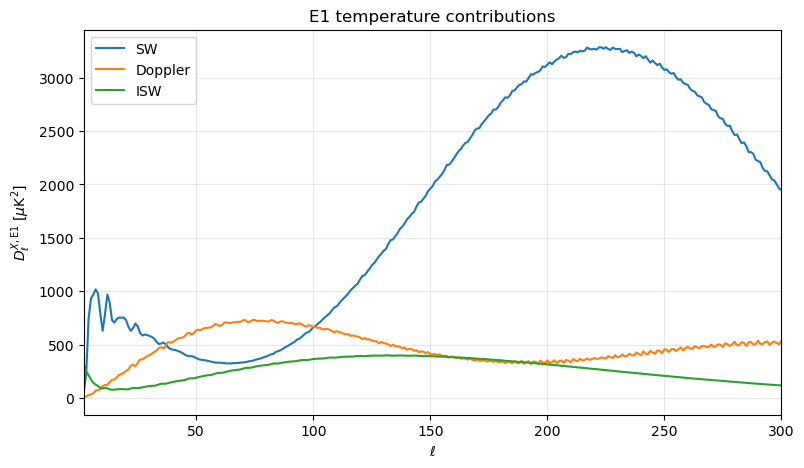

In [17]:
# ==================================================
# Cell 3: E1 transfer functions -> component C_ell
# ==================================================
import numpy as np
import matplotlib.pyplot as plt


A_s = 2.100e-9
n_s = 0.9649
k_pivot = 0.05
T_CMB_uK = 2.7255e6

P_R = A_s * (k_E1 / k_pivot) ** (n_s - 1.0)

weight = (
    k_fund**3
    * g_E1
    * P_R
    / k_E1**3
)

transfer = {
    "SW": transfer_E1["SW"],
    "Doppler": transfer_E1["Doppler"],
    "ISW": (
        transfer_E1["early_ISW"]
        + transfer_E1["late_ISW"]
    ),
}

Cl_E1 = {
    label: np.sum(
        weight[None, :] * delta_lk**2,
        axis=1,
    )
    for label, delta_lk in transfer.items()
}

ell = np.arange(LMAX + 1)

Dl_E1 = {
    label: (
        ell * (ell + 1)
        / (2.0 * np.pi)
        * Cl
        * T_CMB_uK**2
    )
    for label, Cl in Cl_E1.items()
}

plt.figure(figsize=(9, 5))

for label, Dl in Dl_E1.items():
    plt.plot(ell[2:], Dl[2:], label=label)

plt.xlim(2, LMAX)
plt.xlabel(r"$\ell$")
plt.ylabel(r"$D_\ell^{X,\mathrm{E1}}\ [\mu{\rm K}^2]$")
plt.title("E1 temperature contributions")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Construct the harmonic filter

Using the CLASS component spectra, construct a preliminary Aurich-style harmonic filter

$$
\delta T_\ell^{w}
=
\delta T_\ell^{\rm SW}
-
\left(
\delta T_\ell^{\rm Doppler}
+
\delta T_\ell^{\rm ISW}
\right),
$$

where

$$
\delta T_\ell^{\rm ISW}
=
\delta T_\ell^{\rm early\,ISW}
+
\delta T_\ell^{\rm late\,ISW}.
$$

The maximum value over $l$

$$
\delta T_{\max}
=
\max\left(\delta T_\ell^{w}\right)
$$

is then used to define the harmonic weight

$$
w_\ell
=
\exp\!\left[
-
\frac{
\left(\delta T_{\max}-\delta T_\ell^{w}\right)^2
}{
\delta T_{\max}^2
}
\right].
$$

This filter preferentially retains multipoles where the ordinary Sachs–Wolfe contribution dominates over Doppler and ISW.

**Note:** This filter is still based on the standard flat ΛCDM prediction. The E1 topology has not yet been incorporated.

### Flat ΛCDM cosmology

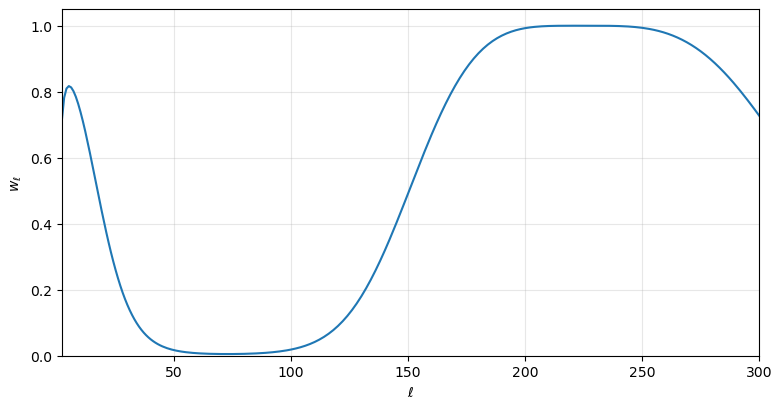

Saved filter data: /hydrarepo/xluo/circles-in-the-sky/SW_Doppler_ISW_filter_lmax300.dat


In [5]:
# Total ISW: early + late together
ell, Dl_ISW = get_tt_component("eisw,lisw")

deltaT_SW = np.sqrt(np.clip(spectra["SW"], 0.0, None))
deltaT_Doppler = np.sqrt(np.clip(spectra["Doppler"], 0.0, None))
deltaT_ISW = np.sqrt(np.clip(Dl_ISW, 0.0, None))

deltaT_w = (
    deltaT_SW
    - deltaT_Doppler
    - deltaT_ISW
)

valid = (ell >= 2) & (ell <= 300)

deltaT_max = np.max(deltaT_w[valid])

w_ell = np.zeros_like(ell, dtype=float)
w_ell[valid] = np.exp(
    -(
        (deltaT_max - deltaT_w[valid]) ** 2
        / deltaT_max**2
    )
)

plt.figure(figsize=(9, 4.5))
plt.plot(ell[valid], w_ell[valid])
plt.xlim(2, 300)
plt.ylim(0, 1.05)
plt.xlabel(r"$\ell$")
plt.ylabel(r"$w_\ell$")
plt.grid(alpha=0.3)
plt.show()

from pathlib import Path

filter_file = Path(
    "/hydrarepo/xluo/circles-in-the-sky/"
    "SW_Doppler_ISW_filter_lmax300.dat"
)

np.savetxt(
    filter_file,
    np.column_stack((ell[valid], w_ell[valid])),
    header="ell  w_ell",
    fmt=["%d", "%.12e"],
)

print("Saved filter data:", filter_file)

### E1 topology

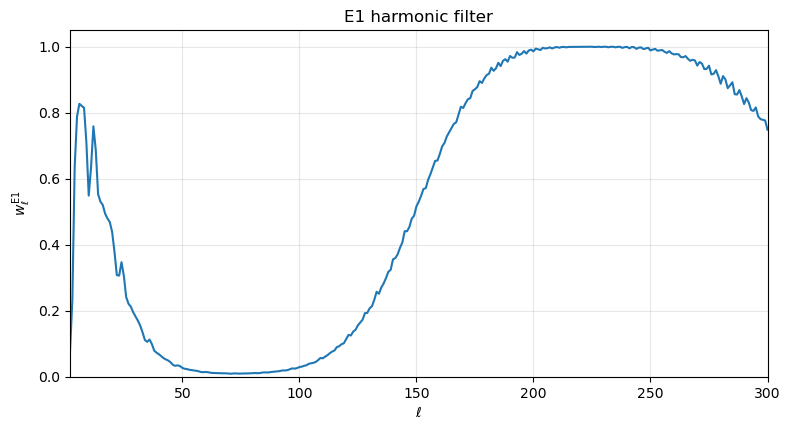

In [18]:
# ==================================================
# Cell 4: construct the E1 harmonic filter
# ==================================================
import numpy as np
import matplotlib.pyplot as plt


deltaT_SW = np.sqrt(np.clip(Dl_E1["SW"], 0.0, None))
deltaT_Doppler = np.sqrt(np.clip(Dl_E1["Doppler"], 0.0, None))
deltaT_ISW = np.sqrt(np.clip(Dl_E1["ISW"], 0.0, None))

deltaT_w = (
    deltaT_SW
    - deltaT_Doppler
    - deltaT_ISW
)

valid = (ell >= 2) & (ell <= LMAX)

deltaT_max = np.max(deltaT_w[valid])

w_ell_E1 = np.zeros(LMAX + 1)

w_ell_E1[valid] = np.exp(
    -(
        (deltaT_max - deltaT_w[valid])**2
        / deltaT_max**2
    )
)

plt.figure(figsize=(9, 4.5))
plt.plot(ell[valid], w_ell_E1[valid])
plt.xlim(2, LMAX)
plt.ylim(0.0, 1.05)
plt.xlabel(r"$\ell$")
plt.ylabel(r"$w_\ell^{\rm E1}$")
plt.title("E1 harmonic filter")
plt.grid(alpha=0.3)
plt.show()